# CSCI 4380 - Data Mining (Final Project)
- Aiden Sagneri
- Anisha Dhawan
- Carla Tu
- Emily Tran
- Joshua Mark
## Project Description
This project attempts to create a data mining model that can accept a dataset, that, by the use of smarthome sensors, record a resident's house-activity, and be able to reliably predict the resident's activity given up to 60 seconds of prior sensor data. To help generalize the model, this project uses two pre-existing datasets to help build the model instead of one: [Orange4Home](https://hal.science/hal-01639673) and [CASAS ____ ](https://pmc.ncbi.nlm.nih.gov/articles/PMC3886862/). The main purpose of this project is to first create this model, and then analyze how well it performs with the two pre-existind datasets, as well as note any interesting findings that were discovered in the process.

---
## Data Preprocessing
You should be able to just run these cells and then collapse the entire section.

In [1]:
# ================================================================================
# import packages
# ================================================================================
import os, math, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import random
import itertools
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

In [2]:
# ================================================================================
# Import datasets
# ================================================================================
# Download the dataset from the web if it doesn't already exist in the current working directory
#
# Dataset (as DataFrame objects) are called:
# - o4h (orange4home dataset)
# - casas (CASAS dataset) 

# --- Orange4Home ---
O4H_DATA_URL = "https://github.com/JCumin/jcumin.github.io/raw/refs/heads/main/orange4home.zip" # Web location (downloads a .zip file)
O4H_ZIP_PATH = "orange4home.zip" # Import (.zip) of the web location 
O4H_CSV_PATH = os.path.join("orange4home", "o4h_all_events.csv") # Location in the .zip of the dataset (.csv file)

if not os.path.exists(O4H_CSV_PATH): # If .csv file not found, get it from the .zip file
    if not os.path.exists(O4H_ZIP_PATH): # If the .zip file does not exist, download from the web
        print("Downloading Orange4Home dataset (about 8 MB)...")
        urllib.request.urlretrieve(O4H_DATA_URL, O4H_ZIP_PATH)
    with zipfile.ZipFile(O4H_ZIP_PATH) as z: # "...get it from the .zip file"
        z.extract("orange4home/o4h_all_events.csv")
    os.remove(O4H_ZIP_PATH); # delete .zip after extracting dataset from it

# Read the dataset (.csv) file
o4h = pd.read_csv(O4H_CSV_PATH)
o4h['Time'] = pd.to_datetime(o4h['Time']) # convert time column to datetime objects
print(f"O4H: Number of events (rows): {o4h.shape[0]:,}")

del O4H_DATA_URL, O4H_ZIP_PATH, O4H_CSV_PATH

# --- CASAS ---
# HH101 is headerless; rows have Date, Time, Sensor, Value, and optional Activity.
CASAS_CSV_PATH = "hh101.csv"  # place this file beside the notebook
casas = pd.read_csv(CASAS_CSV_PATH, header=None,
                    names=["Date", "Time", "Sensor", "Value", "Activity"])
casas["Timestamp"] = pd.to_datetime(casas["Date"] + " " + casas["Time"])
casas = casas.sort_values("Timestamp").reset_index(drop=True)
print(f"CASAS: Number of events (rows): {len(casas):,}")


O4H: Number of events (rows): 746,767
CASAS: Number of events (rows): 222,858


### Dataset Preprocessing
Format, parse, and/or manipulate the original datasets to get formal target variables as well as normalized input variables that the model can eventually use to be trained/tested on 

In [3]:
# ================================================================================
# Data Preprocessing
# ================================================================================

# --- Orange4Home ---
# Variables Saved:
# o4h_windows - a timeline (segmented into 60s windows) with the associated activity 
#   (label) for each window
# X_sensor - a timeline (segmented into 60s windows, each row is one window) that 
#   records the number of changes for each sensor
# o4h_y - the timeline from o4h_windows with only the labels (no start or end time columns)
# o4h_train - the first two weeks of o4h_windows
# o4h_test - the last two weeks of o4h_windows
#
# Other saved variables (idk what to do with them)
# minute, X_clock, X_log, X_bin


# Pull out the label events only (e.g. START:Office|Computing), sorted by time
lab = o4h[o4h['ItemName'] == 'label'].sort_values('Time').reset_index(drop=True)

# Split each label value into two parts:
kind = lab['Value'].str.split(':', n=1).str[0] # the "START" or "STOP" value
name = lab['Value'].str.split(':', n=1).str[1] # the activity being started/stopped (e.g. "Office|Computing")

# Separate labels start and stop tables (maintain sorted-chronology)
starts, stops = lab[kind == 'START'].reset_index(drop=True), lab[kind == 'STOP'].reset_index(drop=True)
assert (name[kind == 'START'].values == name[kind == 'STOP'].values).all() # double-check seperation is done correctly

# Recombine into list of labels with start and stop times (sorted by start-column)
intervals = pd.DataFrame({'Label': name[kind == 'START'].values, 'Start': starts['Time'].values, 'End': stops['Time'].values})
day_order = sorted(intervals['Start'].dt.date.unique())
intervals['DayIndex'] = intervals['Start'].dt.date.map({d: i for i, d in enumerate(day_order)})
intervals['Week'] = intervals['DayIndex'] // 5 + 1
# print(f"{len(o4h_intervals)} activity instances, {o4h_intervals['Label'].nunique()} place|activity labels, {len(day_order)} days")
# print(f"{o4h_intervals}")

WINDOW = '60s'

# Cut/expand every labeled interval into consecutive 60-second windows; a window 
# gets the label it lies in.
win_rows = []
for _, r in intervals.iterrows():
    for t in pd.date_range(r['Start'].floor(WINDOW), r['End'], freq=WINDOW):
        mid = t + pd.Timedelta(WINDOW) / 2
        if r['Start'] <= mid < r['End']:              # the window's midpoint is inside the activity
            win_rows.append((t, r['Label'], r['Week'], r['DayIndex']))
o4h_windows = pd.DataFrame(win_rows, columns=['WindowStart', 'Label', 'Week', 'DayIndex']).drop_duplicates('WindowStart')

# Create a new df where each cell counts the number of updates to a particular 
# sensor (column) is received during that particular window (row)
sensors = o4h[o4h['ItemName'] != 'label'].sort_values(['ItemName', 'Time'])
changes = sensors[sensors['Value'] != sensors.groupby('ItemName')['Value'].shift()].copy()
changes['WindowStart'] = changes['Time'].dt.floor(WINDOW)
counts = changes.groupby(['WindowStart', 'ItemName']).size().unstack(fill_value=0)
constant = sensors.groupby('ItemName')['Value'].nunique() == 1   # 28 sensors never change: no information
sensor_cols = [c for c in counts.columns if not constant[c]]
X_sensor = counts.reindex(o4h_windows['WindowStart'], fill_value=0)[sensor_cols].reset_index(drop=True)

# I'm not sure what this is used for (Copied from hw 3).
# "3) Clock features (kept separate, to measure how much the schedule alone gives away)"
minute = o4h_windows['WindowStart'].dt.hour * 60 + o4h_windows['WindowStart'].dt.minute
X_clock = pd.DataFrame({'clock_sin': np.sin(2 * np.pi * minute / 1440),
                        'clock_cos': np.cos(2 * np.pi * minute / 1440)})

# Finally, create normalized datasets
o4h_y = o4h_windows['Label'].reset_index(drop=True)
o4h_train = (o4h_windows['Week'] <= 2).values   # weeks 1-2 for training
o4h_test = ~o4h_train                       # weeks 3-4 for testing

# Once again, i'm not sure how this is used (copied from hw 3).
X_log = np.log1p(X_sensor)          # change counts are very skewed; log keeps big counts from dominating
X_bin = (X_sensor > 0).astype(int)  # "did this sensor change in the window?" for ID3 and Naive Bayes

print(f"Windows: {len(o4h_windows):,} (train {o4h_train.sum():,}, test {o4h_test.sum():,}), sensor features: {len(sensor_cols)}")
print('\nWindows per label (train / test):')
print(pd.crosstab(o4h_y, np.where(o4h_train, 'train', 'test'))[['train', 'test']].sort_values('train').to_string())

del lab, kind, name, starts, stops, intervals, day_order, win_rows, sensors, changes, counts, constant, sensor_cols

Windows: 10,311 (train 5,282, test 5,029), sensor features: 208

Windows per label (train / test):
col_0                       train  test
Label                                  
Kitchen|Cleaning                3     5
Bathroom|Cleaning               4     5
Bedroom|Cleaning                4     2
Office|Cleaning                 5     5
Entrance|Leaving                7    10
Toilet|Using_the_toilet         8     8
Living_room|Cleaning            9    10
Staircase|Going_down           10     5
Staircase|Going_up             10     8
Bedroom|Dressing               14    16
Kitchen|Preparing              17    13
Entrance|Entering              19    14
Bathroom|Using_the_toilet      23    12
Kitchen|Washing_the_dishes     58    48
Bathroom|Using_the_sink        60    58
Kitchen|Cooking               115    94
Living_room|Eating            126    93
Office|Watching_TV            144   116
Bathroom|Showering            174   155
Bedroom|Napping               197   203
Living_room|Computing

In [4]:
# ================================================================================
# CASAS HH101 preprocessing: match Orange4Home's 60-second windows
# ================================================================================

# Activity boundaries are stored as: Sleep="begin", Sleep="end", etc.
casas_marks = casas["Activity"].str.extract(r'^(.*?)="(begin|end)"$')
casas_events = casas.loc[casas_marks[0].notna(), ["Timestamp"]].copy()
casas_events["Label"] = casas_marks[0].dropna().values
casas_events["Boundary"] = casas_marks[1].dropna().values

# Pair each beginning with the corresponding end for the same activity.
casas_starts = casas_events[casas_events["Boundary"] == "begin"].copy()
casas_ends = casas_events[casas_events["Boundary"] == "end"].copy()
casas_starts["Episode"] = casas_starts.groupby("Label").cumcount()
casas_ends["Episode"] = casas_ends.groupby("Label").cumcount()
casas_intervals = casas_starts[["Label", "Episode", "Timestamp"]].merge(
    casas_ends[["Label", "Episode", "Timestamp"]],
    on=["Label", "Episode"], suffixes=("_start", "_end")
).rename(columns={"Timestamp_start": "Start", "Timestamp_end": "End"}).sort_values("Start")

assert len(casas_starts) == len(casas_ends) == len(casas_intervals)
assert (casas_intervals["Start"] < casas_intervals["End"]).all()

# Label the 60-second windows using the same midpoint rule as Orange4Home.
casas_window_rows = []
for r in casas_intervals.itertuples():
    for t in pd.date_range(r.Start.floor(WINDOW), r.End, freq=WINDOW):
        mid = t + pd.Timedelta(WINDOW) / 2
        if r.Start <= mid < r.End:
            casas_window_rows.append((t, r.Label))

casas_windows = (pd.DataFrame(casas_window_rows, columns=["WindowStart", "Label"])
                 .drop_duplicates("WindowStart").sort_values("WindowStart").reset_index(drop=True))

# Count sensor state changes per minute, just as Orange4Home does.
casas_sensors = casas.sort_values(["Sensor", "Timestamp"])
casas_changes = casas_sensors[
    casas_sensors["Value"].ne(casas_sensors.groupby("Sensor")["Value"].shift())
].copy()
casas_changes["WindowStart"] = casas_changes["Timestamp"].dt.floor(WINDOW)
casas_counts = casas_changes.groupby(["WindowStart", "Sensor"]).size().unstack(fill_value=0)
casas_X = casas_counts.reindex(casas_windows["WindowStart"], fill_value=0).reset_index(drop=True)
casas_y = casas_windows["Label"].reset_index(drop=True)

print(f"CASAS episodes: {len(casas_intervals):,}")
print(f"CASAS windows: {len(casas_X):,}; activity labels: {casas_y.nunique()}; sensor features: {casas_X.shape[1]}")
print("\nMost common CASAS activities:")
print(casas_y.value_counts().head(10))

CASAS episodes: 2,645
CASAS windows: 72,559; activity labels: 34; sensor features: 6

Most common CASAS activities:
Label
Sleep               22998
Watch_TV            22498
Sleep_Out_Of_Bed    14974
Read                 2839
Relax                1628
Personal_Hygiene      892
Bathe                 878
Eat_Breakfast         873
Toilet                823
Dress                 725
Name: count, dtype: int64


### Data Model
The classes and functions that represent the learning model and its behaviors.

#### Utility Functions

In [5]:
def count_items(items):
    counts = {}
    for x in items:
        counts[x] = counts.get(x, 0) + 1
    return counts

def class_probabilities(labels):
    """
       Takes a 1D list of event outcomes (y).

       Returns a 1D list where each cell represents the probability of each unique outcome listed in labels (that occured in y)
    """
    total = float(len(labels))
    counts = count_items(labels)
    return [counts[label] / total for label in counts]

def entropy(probabilities):
    """ 
        Returns the entropy of (the average number of bits it takes to represent an) event with the given probabilities.
    """
    return sum(-p * math.log2(p) for p in probabilities if p > 0)

def data_entropy(labels):
    """
        Returns the entropy of (the average number of bits it takes to represent) the given events
    """
    return entropy(class_probabilities(labels))

def gini_impurity(labels):
    """
    DONE: Calculate the Gini impurity of a list of labels.
    Formula: 1 - sum((p_i)^2)
    """
    p = class_probabilities(labels);
    p2 = [i ** 2 for i in p];
    s = sum(p2);
    return 1 - s;

def _same_category(left, right):
    # Treat a missing floating-point category as equal to another missing value.
    if left == right:
        return True;
    return left != left and right != right;

def weighted_gini(X, y, attribute, split_value):
    """
    DONE: Calculate the weighted Gini impurity of a binary split.
    The split is defined by: x[attribute] == split_value (True branch)
                             x[attribute] != split_value (False branch)
    """
    # A tuple allows the true branch to contain a subset of a categorical feature's values.
    split_values = split_value if isinstance(split_value, tuple) else (split_value,);
    t_branch = [
        label for row, label in zip(X, y)
        if any(_same_category(row[attribute], value) for value in split_values)
    ];
    f_branch = [
        label for row, label in zip(X, y)
        if not any(_same_category(row[attribute], value) for value in split_values)
    ];

    total = len(X);
    t_ratio = len(t_branch) / total;
    f_ratio = len(f_branch) / total;

    return (t_ratio * gini_impurity(t_branch)) + (f_ratio * gini_impurity(f_branch));

def bootstrap_sample(X, y):
    """
    Generate a bootstrap sample from a training dataset.

    A bootstrap sample is constructed by randomly selecting observations WITH replacement until the generated sample
    contains the same number of observations as the original dataset.

    Parameters
    ----------
    X : pandas.DataFrame
        Training features.

    y : pandas.Series
        Training labels.

    Returns
    -------
    X_boot : pandas.DataFrame
        Bootstrap-sampled feature matrix.

    y_boot : pandas.Series
        Bootstrap-sampled labels.

    indices : list
        Zero-based row positions selected from the input, used for OOB evaluation.

    Notes
    -----
    - Duplicate observations are expected.
    - Some observations may not appear in the sample.
    - The returned indices will later be used for Out-of-Bag (OOB) evaluation.
    """

    if len(X) != len(y):
        raise ValueError("X and y must contain the same number of observations.")
    if len(X) == 0:
        raise ValueError("Cannot bootstrap an empty dataset.")

    indices = np.random.choice(len(X), size=len(X), replace=True).tolist()
    X_boot = X.iloc[indices].reset_index(drop=True)
    y_boot = y.iloc[indices].reset_index(drop=True)

    return X_boot, y_boot, indices

#### Model Classes
The main class is CARTTree, which is a decision tree that splits each node according to Gini Impurity, with a specific control for decision tree depth. RandomForestTree extends this CARTTree with changes to randomly select the attribute (from a set of candidates) to split the node on; and RandomForest implements multiple instances of RandomForestTree to aggregate multiple decision trees and combine the results/final behaviors. 

In [6]:
class CARTTree:
    class _Leaf:
        def __init__(self, value):
            self.value = value

        def predict(self, x):
            return self.value

    class _BinarySplit:
        def __init__(self, attribute, split_value, true_branch, false_branch, default_value):
            self.attribute = attribute
            self.split_value = split_value
            self.true_branch = true_branch
            self.false_branch = false_branch
            self.default_value = default_value

        def predict(self, x):
            # DONE: Implement the prediction traversal for a binary split.
            # If x[self.attribute] == self.split_value, go to true_branch.
            # Otherwise, go to false_branch. Handle missing attributes safely.
            # Missing attributes fall back to the majority class stored at this node.
            if self.attribute not in x: return self.default_value;
            
            split_values = self.split_value if isinstance(self.split_value, tuple) else (self.split_value,);
            
            if any(_same_category(x[self.attribute], value) for value in split_values):
                return self.true_branch.predict(x);
            return self.false_branch.predict(x);

    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1, min_impurity_decrease=0.0):
        self.root = None
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease

    def fit(self, X, y):
        attributes = list(X[0].keys())
        self.root = self._build_tree(X, y, attributes, depth=0)

    def predict(self, x):
        if self.root is None:
            raise ValueError("Tree not trained")
        return self.root.predict(x)

    def predict_all(self, X):
        # Apply the single-example prediction method to every feature row.
        return [self.predict(x) for x in X];

    def accuracy(self, X, y):
        correct = sum(1 for x_i, y_i in zip(X, y) if self.predict(x_i) == y_i)
        return correct / len(y)

    def _partition_by(self, X, y, attribute, split_value):
        """
        DONE: Partition the dataset into two subsets (True and False) 
        based on whether x[attribute] == split_value.
        Returns: (X_true, y_true), (X_false, y_false)
        """
        # Preserve feature-row and target-label alignment in both branches.
        split_values = split_value if isinstance(split_value, tuple) else (split_value,);
        X_true = [];
        y_true = [];
        X_false = [];
        y_false = [];
        for row, label in zip(X, y):
            is_true = any(_same_category(row[attribute], value) for value in split_values);
            if is_true:
                X_true.append(row);
                y_true.append(label);
            else:
                X_false.append(row);
                y_false.append(label);
        return (X_true, y_true), (X_false, y_false);

    def _select_candidate_attributes(self, attributes):
        return attributes

    def _build_tree(self, X, y, attributes, depth):
        """
        DONE: Implement the recursive tree-building logic with stopping criteria.
        
        Stopping Criteria Checklist:
        1. Are all labels identical? (Pure node)
        2. Is depth >= self.max_depth?
        3. Is len(y) < self.min_samples_split?
        If any of the above are true, return a _Leaf.

        Split Logic:
        1. Calculate current node's Gini impurity.
        2. Find best attribute and split_value that minimizes weighted Gini.
        3. Calculate impurity decrease: (current_gini - weighted_gini).
        
        Post-Split Checks:
        1. Is impurity decrease < self.min_impurity_decrease?
        2. Does either the true or false branch have fewer than self.min_samples_leaf rows?
        If either is true, cancel the split and return a _Leaf.
        
        Otherwise, recursively build true and false branches and return a _BinarySplit.
        """
        # --- Stopping Criterea ---
        # Use the node's majority label for stopping leaves and unseen-value fallback.
        label_counts = count_items(y);
        majority_label = max(label_counts, key=label_counts.get);

        # Stop on pure labels, depth limit, or insufficient samples.
        if (len(label_counts) == 1) or (self.max_depth is not None and depth >= self.max_depth) or (len(y) < self.min_samples_split):
            return self._Leaf(majority_label);

        # --- Split Logic ---
        # Find every non-duplicate binary grouping of the observed categories.
        best_attr, best_split_val, best_w_gini = None, None, float("inf");
        for attribute in self._select_candidate_attributes(attributes):
            categories = [];
            for row in X:
                value = row[attribute];
                if not any(_same_category(value, seen) for seen in categories):
                    categories.append(value);
            if len(categories) < 2: continue;

            # Fix the first value on the true side so complements are scored only once.
            for subset_size in range(len(categories) - 1):
                for other_values in itertools.combinations(categories[1:], subset_size):
                    split_values = (categories[0],) + other_values;
                    split_gini = weighted_gini(X, y, attribute, split_values);
                    if split_gini < best_w_gini:
                        best_attr = attribute;
                        best_split_val = split_values;
                        best_w_gini = split_gini;

        # Stop if all remaining attributes are constant at this node.
        if best_attr is None:
            return self._Leaf(majority_label);

        current_gini = gini_impurity(y);
        impurity_decrease = current_gini - best_w_gini;
        (X_true, y_true), (X_false, y_false) = self._partition_by(
            X, y, best_attr, best_split_val
        );

        # --- Post-Split Checks ---
        # Reject splits that fail the configured impurity or child-size thresholds.
        if impurity_decrease < self.min_impurity_decrease or len(y_true) < self.min_samples_leaf or len(y_false) < self.min_samples_leaf:
            return self._Leaf(majority_label);

        # Reuse available attributes in both recursive branches, as CART permits.
        true_branch = self._build_tree(X_true, y_true, attributes, depth + 1);
        false_branch = self._build_tree(X_false, y_false, attributes, depth + 1);
        return self._BinarySplit(
            best_attr, best_split_val, true_branch, false_branch, majority_label
        );

In [7]:
class RandomForestTree(CARTTree):
    """
    Extension of the CARTTree implementation that supports random feature selection during split evaluation.

    Expected Behavior
    -----------------
    When searching for the best split at a node, evaluate only a randomly selected subset of candidate attributes rather than all available attributes.
    """

    def __init__(self, max_features="sqrt", **kwargs):
        """
        Parameters
        ----------
        max_features : int, str, or None
            Controls how many attributes are considered when searching for the best split.

        **kwargs
            Additional parameters passed to CARTTree.
        """
        self.max_features = max_features
        super().__init__(**kwargs)

    def _select_candidate_attributes(self, attributes):
        """
        Select the attributes that will be evaluated for splitting at the current node.

        Parameters
        ----------
        attributes : list
            Available attributes at the current node.

        Returns
        -------
        list
            Randomly selected candidate attributes.
        """
        return select_random_features(attributes, self.max_features)

In [8]:
class RandomForest:
    """
    Random Forest classifier built using your CART implementation.

    Each tree must be trained using:

    1. A bootstrap sample of the training data.
    2. Random feature selection during split evaluation.

    Final predictions should be generated using majority voting across all trees in the ensemble.
    """

    def __init__(
        self,
        n_trees=10,
        max_depth=None,
        max_features="sqrt"
    ):
        """
        Parameters
        ----------
        n_trees : int
            Number of trees in the forest.

        max_depth : int or None
            Maximum depth of each tree.

        max_features : int, str, or None
            Feature-selection strategy passed to each RandomForestTree.
        """
        if not isinstance(n_trees, int) or isinstance(n_trees, bool) or n_trees < 1:
            raise ValueError("n_trees must be a positive integer.")
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.max_features = max_features
        self.trees = []
        self.bootstrap_indices = []

    def fit(self, X, y):
        """
        Train the Random Forest.

        Requirements
        ------------
        For each tree:

        1. Create a bootstrap sample.
        2. Train a RandomForestTree on that sample.
        3. Store the tree for future predictions.

        Consider storing bootstrap indices to support Out-of-Bag (OOB) evaluation.
        """
        if len(X) != len(y):
            raise ValueError("X and y must contain the same number of observations.")
        if len(X) == 0:
            raise ValueError("Cannot fit a random forest on an empty dataset.")

        self.trees = []
        self.bootstrap_indices = []
        for _ in range(self.n_trees):
            X_boot, y_boot, indices = bootstrap_sample(X, y)
            tree = RandomForestTree(max_features=self.max_features, max_depth=self.max_depth)
            tree.fit(X_boot.to_dict(orient="records"), y_boot.tolist())
            self.trees.append(tree)
            self.bootstrap_indices.append(indices)
        return self

    def predict(self, X):
        """
        Predict class labels for a dataset.

        Requirements
        ------------
        1. Obtain predictions from every tree.
        2. Use majority voting to determine the final prediction for each observation.

        Returns
        -------
        list
            Predicted labels.
        """
        if not self.trees:
            raise ValueError("The random forest has not been fitted yet.")
        records = X.to_dict(orient="records") if isinstance(X, pd.DataFrame) else list(X)
        if not records:
            return []
        tree_predictions = [tree.predict_all(records) for tree in self.trees]
        return [
            self.majority_vote([predictions[i] for predictions in tree_predictions])
            for i in range(len(records))
        ]

    def majority_vote(self, predictions):
        """
        Determine the most frequently predicted class.

        Parameters
        ----------
        predictions : list
            Predictions collected from all trees.

        Returns
        -------
        object
            Majority class label.
        """
        if not predictions:
            raise ValueError("Cannot vote on an empty set of predictions.")
        return Counter(predictions).most_common(1)[0][0]

---
## Data Mining
Creating an instance of the data model and training it on the preprocessed data (Orange4Home and CASAS____)

In [9]:
# ================================================================================
# Data Preprocessing
# ================================================================================

# --- Orange4Home ---
o4h_part_i = int(X_sensor.shape[0]*0.8) # the index to partition o4h into training and testing sets

# training set should be 80% of total data
o4h_train_X = X_sensor.iloc[:o4h_part_i] # pull input from X_sensor
o4h_train_y = o4h_y.iloc[:o4h_part_i] # pull output from o4h_y

# testing set should be the remaining 20% of total data
o4h_test_X = X_sensor.iloc[o4h_part_i:]
o4h_test_y = o4h_y.iloc[o4h_part_i:]

# build, train, and test model
# Use sklearn's already-imported Random Forest for an executable comparison.
# The group's custom RandomForest classes above remain unchanged.
model = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=5,
                               random_state=42, n_jobs=-1)
model.fit(o4h_train_X, o4h_train_y)
o4h_predictions = model.predict(o4h_test_X)

In [10]:
# --- CASAS ---
# Use the same chronological 80/20 split and Random Forest settings as Orange4Home.
casas_part_i = int(len(casas_X) * 0.8)
casas_train_X, casas_test_X = casas_X.iloc[:casas_part_i], casas_X.iloc[casas_part_i:]
casas_train_y, casas_test_y = casas_y.iloc[:casas_part_i], casas_y.iloc[casas_part_i:]

casas_model = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=5,
                                     random_state=42, n_jobs=-1)
casas_model.fit(casas_train_X, casas_train_y)
casas_predictions = casas_model.predict(casas_test_X)
print(f"CASAS: {len(casas_train_X):,} training windows, {len(casas_test_X):,} testing windows")

CASAS: 58,047 training windows, 14,512 testing windows


---
## Analysis and Conclusions

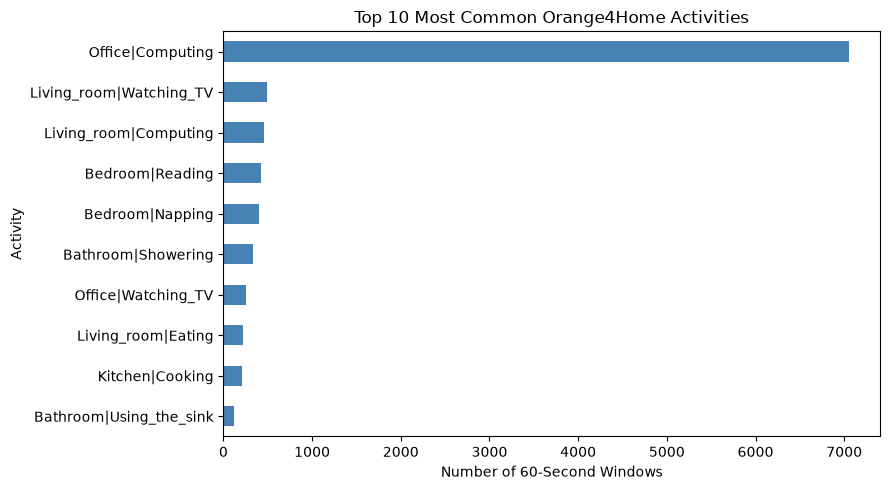

In [11]:
# Top 10 most common Orange4Home activities
o4h_y.value_counts().head(10).sort_values().plot(
    kind="barh", figsize=(9, 5), color="steelblue"
)

plt.title("Top 10 Most Common Orange4Home Activities")
plt.xlabel("Number of 60-Second Windows")
plt.ylabel("Activity")
plt.tight_layout()
plt.show()

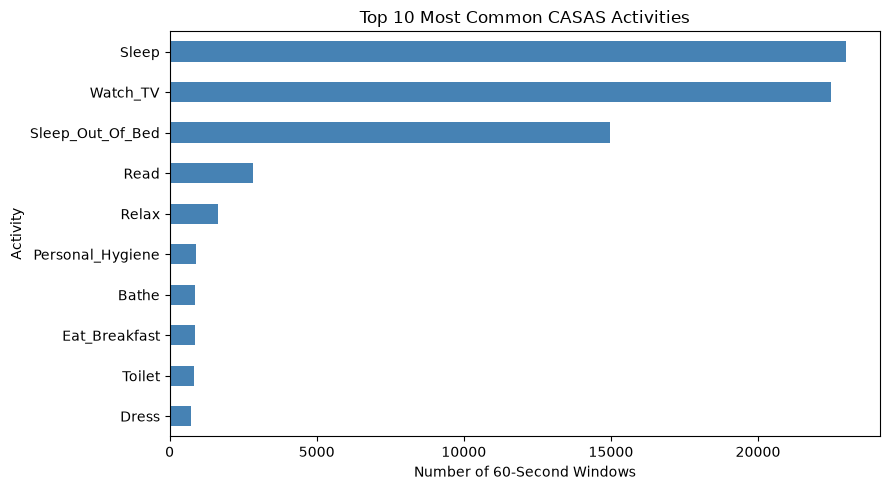

In [12]:
# Top 10 most common CASAS activities
casas_y.value_counts().head(10).sort_values().plot(
    kind="barh", figsize=(9, 5), color="steelblue"
)

plt.title("Top 10 Most Common CASAS Activities")
plt.xlabel("Number of 60-Second Windows")
plt.ylabel("Activity")
plt.tight_layout()
plt.show()

    Dataset  Training windows  Testing windows  Majority baseline  Accuracy  Macro F1  Weighted F1
Orange4Home              8248             2063              0.731     0.925     0.598        0.915
CASAS HH101             58047            14512              0.322     0.529     0.123        0.445


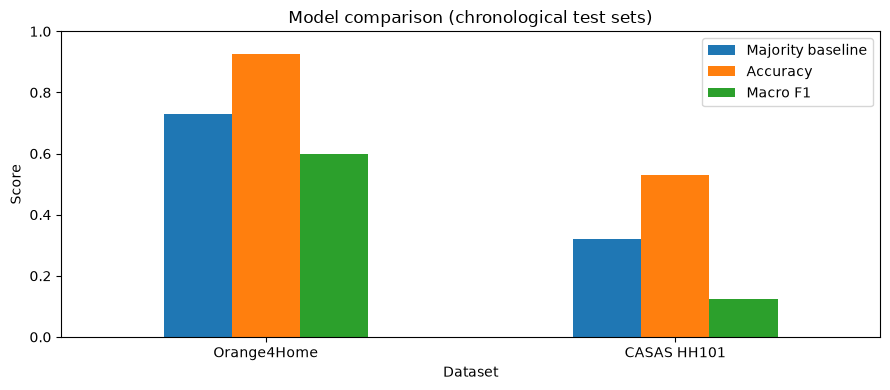


CASAS performance for the 12 most common test activities:
                  precision  recall  f1-score  support
Label                                                 
Watch_TV              0.715   0.499     0.588   5096.0
Sleep                 0.475   0.996     0.643   4668.0
Sleep_Out_Of_Bed      0.000   0.000     0.000   1509.0
Relax                 0.000   0.000     0.000    637.0
Read                  0.000   0.000     0.000    566.0
Personal_Hygiene      0.466   0.531     0.496    262.0
Dress                 0.658   0.244     0.356    213.0
Toilet                0.432   0.194     0.268    196.0
Bathe                 0.467   0.549     0.505    195.0
Phone                 0.000   0.000     0.000    171.0
Entertain_Guests      0.000   0.000     0.000    147.0
Cook_Breakfast        0.326   0.909     0.480    143.0


In [13]:
from sklearn.metrics import classification_report

# Compare performance to a simple model that always guesses the training majority class.
def summarize_results(name, train_y, test_y, predicted):
    majority = train_y.value_counts().idxmax()
    return {
        "Dataset": name,
        "Training windows": len(train_y),
        "Testing windows": len(test_y),
        "Majority baseline": (test_y == majority).mean(),
        "Accuracy": accuracy_score(test_y, predicted),
        "Macro F1": f1_score(test_y, predicted, average="macro", zero_division=0),
        "Weighted F1": f1_score(test_y, predicted, average="weighted", zero_division=0),
    }

results = pd.DataFrame([
    summarize_results("Orange4Home", o4h_train_y, o4h_test_y, o4h_predictions),
    summarize_results("CASAS HH101", casas_train_y, casas_test_y, casas_predictions),
])
print(results.round(3).to_string(index=False))

results.set_index("Dataset")[["Majority baseline", "Accuracy", "Macro F1"]].plot(
    kind="bar", figsize=(9, 4), rot=0, ylim=(0, 1), title="Model comparison (chronological test sets)")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

# Inspect which CASAS activities are well recognized vs missed.
casas_report = pd.DataFrame(classification_report(
    casas_test_y, casas_predictions, output_dict=True, zero_division=0
)).T
print("\nCASAS performance for the 12 most common test activities:")
print(casas_report.loc[casas_test_y.value_counts().head(12).index,
                       ["precision", "recall", "f1-score", "support"]].round(3).to_string())

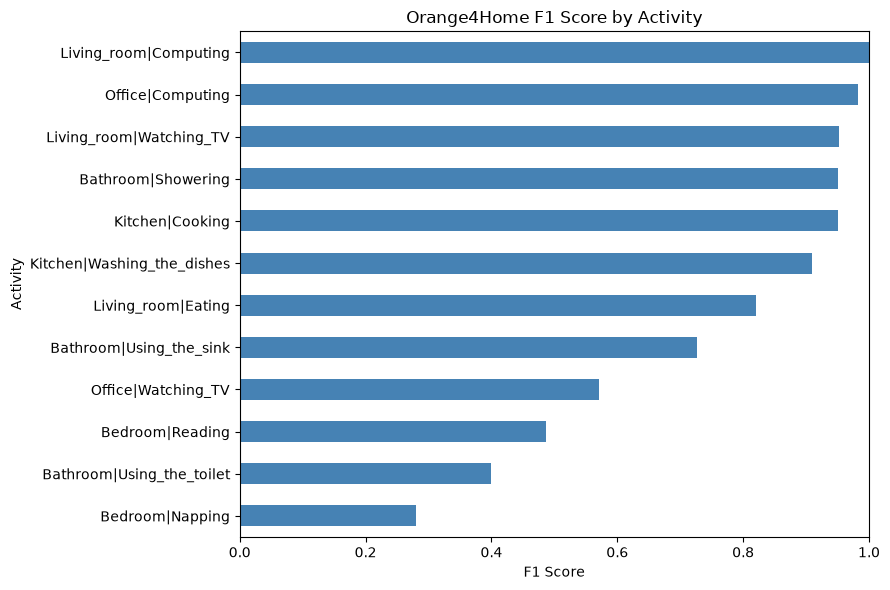

In [14]:
# Orange4Home classification report
o4h_report = pd.DataFrame(classification_report(
    o4h_test_y, o4h_predictions, output_dict=True, zero_division=0
)).T

# F1 scores for the 12 most common Orange4Home test activities
top_activities = o4h_test_y.value_counts().head(12).index

o4h_report.loc[top_activities, "f1-score"].sort_values().plot(
    kind="barh", figsize=(9, 6), color="steelblue"
)

plt.title("Orange4Home F1 Score by Activity")
plt.xlabel("F1 Score")
plt.ylabel("Activity")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

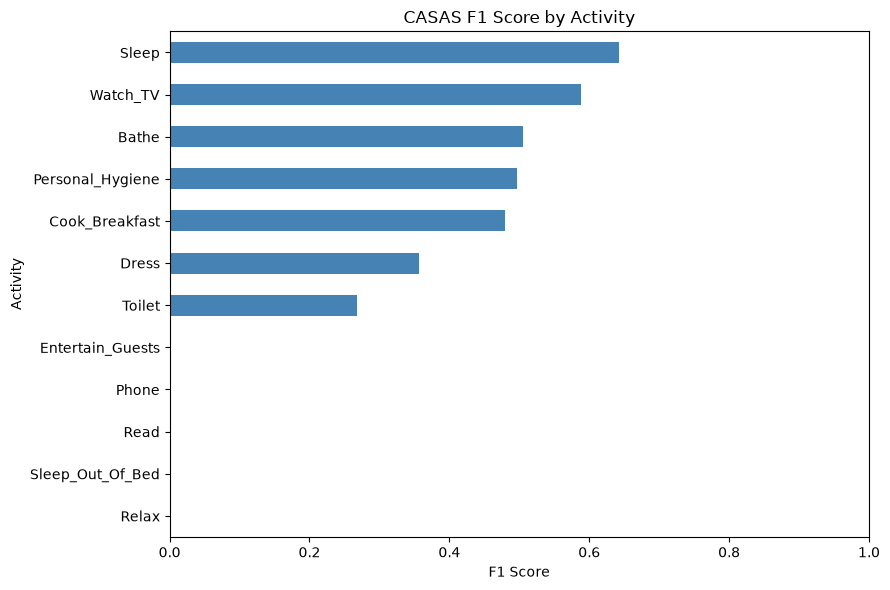

In [15]:
# F1 scores for the 12 most common CASAS test activities
top_activities = casas_test_y.value_counts().head(12).index

casas_report.loc[top_activities, "f1-score"].sort_values().plot(
    kind="barh", figsize=(9, 6), color="steelblue"
)

plt.title("CASAS F1 Score by Activity")
plt.xlabel("F1 Score")
plt.ylabel("Activity")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

In [16]:
# Orange4Home experiment: sensor counts + time of day
o4h_X_with_clock = pd.concat([X_sensor, X_clock], axis=1)

o4h_clock_model = RandomForestClassifier(
    n_estimators=100, max_depth=12,
    min_samples_leaf=5, random_state=42, n_jobs=-1
)

o4h_clock_model.fit(
    o4h_X_with_clock.iloc[:o4h_part_i], o4h_train_y
)

o4h_clock_predictions = o4h_clock_model.predict(
    o4h_X_with_clock.iloc[o4h_part_i:]
)

print("Orange4Home sensor-only accuracy:",
      round(accuracy_score(o4h_test_y, o4h_predictions), 3))

print("Orange4Home sensor + clock accuracy:",
      round(accuracy_score(o4h_test_y, o4h_clock_predictions), 3))

print("Orange4Home sensor-only macro F1:",
      round(f1_score(o4h_test_y, o4h_predictions, average="macro", zero_division=0), 3))

print("Orange4Home sensor + clock macro F1:",
      round(f1_score(o4h_test_y, o4h_clock_predictions, average="macro", zero_division=0), 3))

Orange4Home sensor-only accuracy: 0.925
Orange4Home sensor + clock accuracy: 0.958
Orange4Home sensor-only macro F1: 0.598
Orange4Home sensor + clock macro F1: 0.645


In [17]:
# Additional CASAS experiment: sensor counts + time of day
casas_minute = casas_windows["WindowStart"].dt.hour * 60 + casas_windows["WindowStart"].dt.minute
casas_clock = pd.DataFrame({
    "clock_sin": np.sin(2 * np.pi * casas_minute / 1440),
    "clock_cos": np.cos(2 * np.pi * casas_minute / 1440),
})
casas_X_with_clock = pd.concat([casas_X, casas_clock], axis=1)

casas_clock_model = RandomForestClassifier(n_estimators=100, max_depth=12,
                                           min_samples_leaf=5, random_state=42, n_jobs=-1)
casas_clock_model.fit(casas_X_with_clock.iloc[:casas_part_i], casas_train_y)
casas_clock_predictions = casas_clock_model.predict(casas_X_with_clock.iloc[casas_part_i:])

print("CASAS sensor-only accuracy:", round(accuracy_score(casas_test_y, casas_predictions), 3))
print("CASAS sensor + clock accuracy:", round(accuracy_score(casas_test_y, casas_clock_predictions), 3))
print("CASAS sensor-only macro F1:", round(f1_score(casas_test_y, casas_predictions, average="macro", zero_division=0), 3))
print("CASAS sensor + clock macro F1:", round(f1_score(casas_test_y, casas_clock_predictions, average="macro", zero_division=0), 3))

CASAS sensor-only accuracy: 0.529
CASAS sensor + clock accuracy: 0.746
CASAS sensor-only macro F1: 0.123
CASAS sensor + clock macro F1: 0.311


,Dataset,Features,Accuracy,Macro F1
0,Orange4Home,Sensor Only,0.925,0.598
1,Orange4Home,Sensor + Time,0.958,0.645
2,CASAS,Sensor Only,0.529,0.123
3,CASAS,Sensor + Time,0.746,0.311


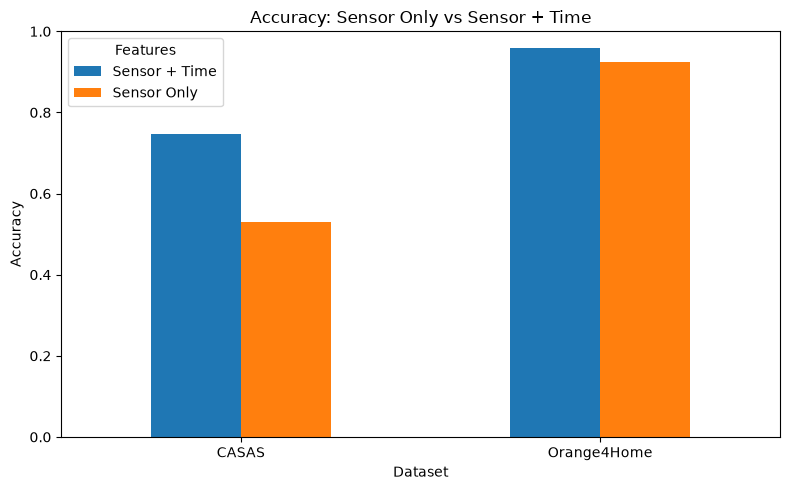

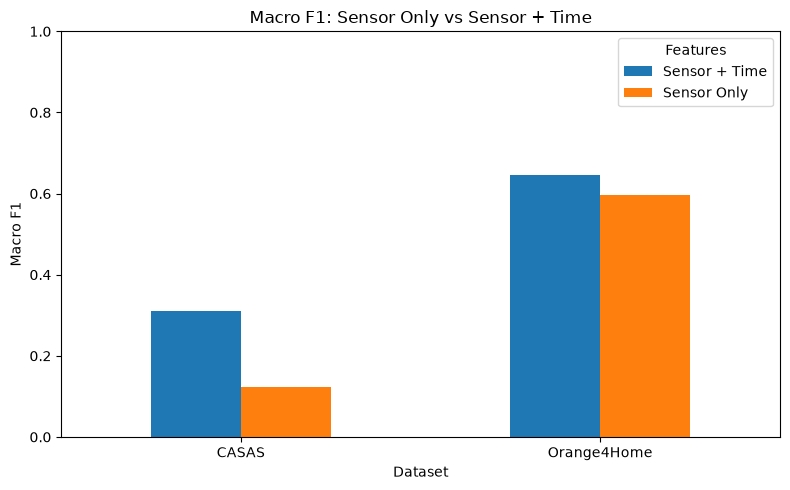

In [18]:
# Compare sensor-only and sensor + time models
comparison = pd.DataFrame({
    "Dataset": ["Orange4Home", "Orange4Home", "CASAS", "CASAS"],
    "Features": ["Sensor Only", "Sensor + Time"] * 2,
    "Accuracy": [
        accuracy_score(o4h_test_y, o4h_predictions),
        accuracy_score(o4h_test_y, o4h_clock_predictions),
        accuracy_score(casas_test_y, casas_predictions),
        accuracy_score(casas_test_y, casas_clock_predictions)
    ],
    "Macro F1": [
        f1_score(o4h_test_y, o4h_predictions, average="macro", zero_division=0),
        f1_score(o4h_test_y, o4h_clock_predictions, average="macro", zero_division=0),
        f1_score(casas_test_y, casas_predictions, average="macro", zero_division=0),
        f1_score(casas_test_y, casas_clock_predictions, average="macro", zero_division=0)
    ]
})

display(comparison.round(3))

for metric in ["Accuracy", "Macro F1"]:
    comparison.pivot(index="Dataset", columns="Features", values=metric).plot(
        kind="bar", figsize=(8, 5), rot=0, ylim=(0, 1)
    )
    plt.title(f"{metric}: Sensor Only vs Sensor + Time")
    plt.ylabel(metric)
    plt.tight_layout()
    plt.show()